# K-Means with Immediate Centroid Update on Iris Dataset

Iris dataset using Petal Length and Petal Width.

## 1. Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, silhouette_score
)

## 2. Load Iris Dataset

In [2]:
iris = load_iris()

X = iris.data[:, 2:4]
y = iris.target

print("Dataset shape:", X.shape)
print("Features:", iris.feature_names[2:4])
print("Classes:", iris.target_names)

Dataset shape: (150, 2)
Features: ['petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


## 3. Scatter Plot

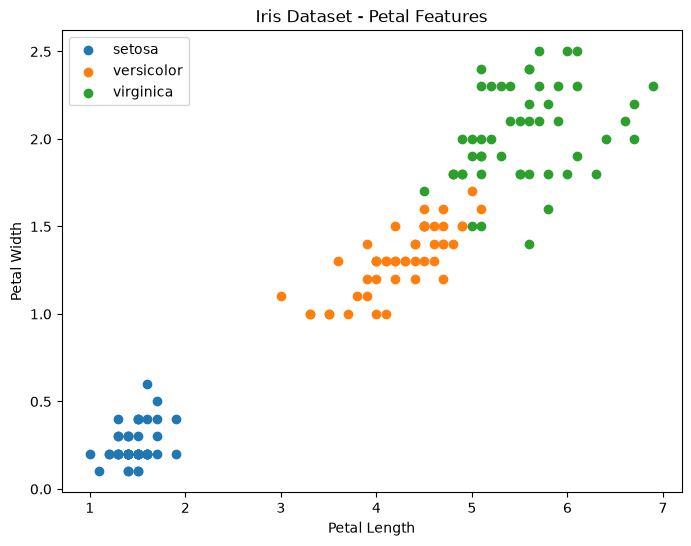

In [3]:
plt.figure(figsize=(8, 6))

for i, name in enumerate(iris.target_names):
    plt.scatter(X[y == i, 0], X[y == i, 1], label=name)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Iris Dataset - Petal Features")
plt.legend()
plt.show()

## 4. Train-Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


## 5. Algorithm

In [5]:
def kmeans_immediate(X, k, max_iter=100):
    centroids = X[np.random.choice(len(X), k, replace=False)].copy()

    for iteration in range(1, max_iter + 1):
        old_centroids = centroids.copy()
        labels = []

        for x in X:
            distances = np.sum((centroids - x) ** 2, axis=1)
            cluster = np.argmin(distances)
            labels.append(cluster)
            centroids[cluster] = (centroids[cluster] + x) / 2

        labels = np.array(labels)
        if np.allclose(old_centroids, centroids):
            break

    return centroids, labels, iteration

## 6. Train Model

In [6]:
np.random.seed(42)
k = 3
centroids, train_labels, iterations = kmeans_immediate(X_train, k)
print("Number of clusters:", k)
print("Total iterations:", iterations)
print("\nCentroids:")
print(centroids)

Number of clusters: 3
Total iterations: 3

Centroids:
[[4.53937928 1.41691616]
 [1.4473276  0.19456026]
 [5.76038856 2.07877828]]


## 7. Cluster Visualization

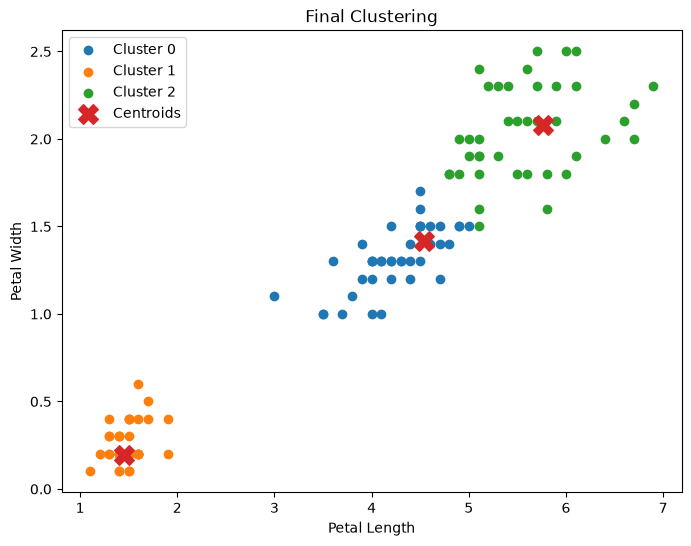

In [7]:
plt.figure(figsize=(8, 6))
for i in range(k):
    plt.scatter(X_train[train_labels == i, 0], X_train[train_labels == i, 1], label=f"Cluster {i}")
plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200, label="Centroids")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Final Clustering")
plt.legend()
plt.show()

## 8. Predict Test Clusters

In [8]:
def predict_clusters(X, centroids):
    labels = []
    for x in X:
        distances = np.sum((centroids - x) ** 2, axis=1)
        labels.append(np.argmin(distances))
    return np.array(labels)

test_labels = predict_clusters(X_test, centroids)
print("Test cluster labels:")
print(test_labels)

Test cluster labels:
[1 0 0 0 1 0 1 1 2 0 2 2 2 0 1 1 1 0 0 0 1 2 0 2 2 0 0 1 2 1]


## 9. Map Clusters to Iris Classes

In [9]:
cluster_to_class = {}

for cluster in range(k):
    classes = y_train[train_labels == cluster]
    if len(classes) > 0:
        values, counts = np.unique(classes, return_counts=True)
        cluster_to_class[cluster] = values[np.argmax(counts)]

print("Cluster mapping:", cluster_to_class)

Cluster mapping: {0: np.int64(1), 1: np.int64(0), 2: np.int64(2)}


## 10. Accuracy, Precision, Recall and F1-Score

In [10]:
y_train_pred = np.array([cluster_to_class[label] for label in train_labels])
y_test_pred = np.array([cluster_to_class[label] for label in test_labels])

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_test_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_test_pred, average="weighted", zero_division=0)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Training Accuracy: 0.9583333333333334
Testing Accuracy: 0.9333333333333333
Precision: 0.9444444444444445
Recall: 0.9333333333333333
F1-Score: 0.9326599326599326


## 11. Confusion Matrix

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


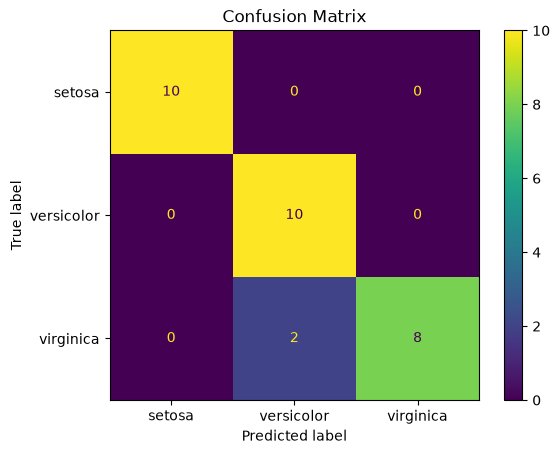

In [11]:
cm = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

## 12. Silhouette Score and Inertia

In [12]:
silhouette = silhouette_score(X_train, train_labels)

inertia = 0
for i in range(k):
    points = X_train[train_labels == i]
    inertia += np.sum((points - centroids[i]) ** 2)

print("Silhouette Score:", silhouette)
print("Inertia:", inertia)

Silhouette Score: 0.6680906736575565
Inertia: 29.49754404415782


## 13. Final Performance Summary

In [13]:
print("\n========== PERFORMANCE SUMMARY ==========")
print("Clusters:", k)
print("Iterations:", iterations)
print("Inertia:", inertia)
print("Silhouette Score:", silhouette)
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)


========== PERFORMANCE SUMMARY ==========
Clusters: 3
Iterations: 3
Inertia: 29.49754404415782
Silhouette Score: 0.6680906736575565
Training Accuracy: 0.9583333333333334
Testing Accuracy: 0.9333333333333333
Precision: 0.9444444444444445
Recall: 0.9333333333333333
F1-Score: 0.9326599326599326


## 14. Final Cluster Plot

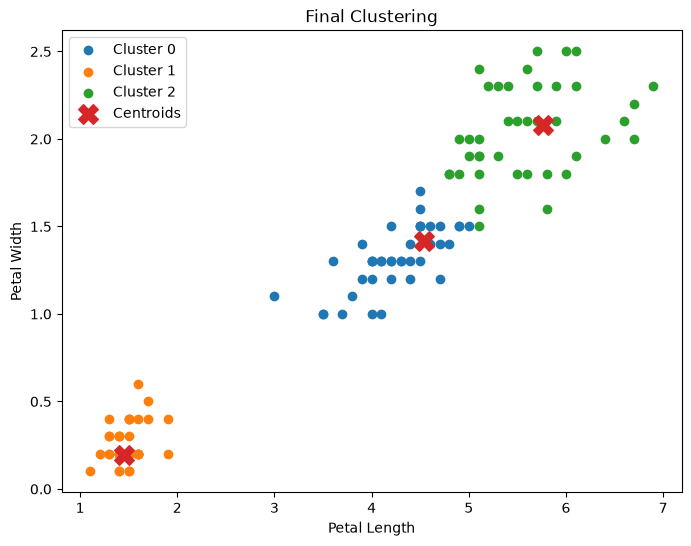

In [14]:
plt.figure(figsize=(8, 6))
for i in range(k):
    plt.scatter(X_train[train_labels == i, 0], X_train[train_labels == i, 1], label=f"Cluster {i}")
plt.scatter(centroids[:, 0], centroids[:, 1], marker="X", s=200, label="Centroids")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Final Clustering")
plt.legend()
plt.show()

## 15. Actual Test Classes

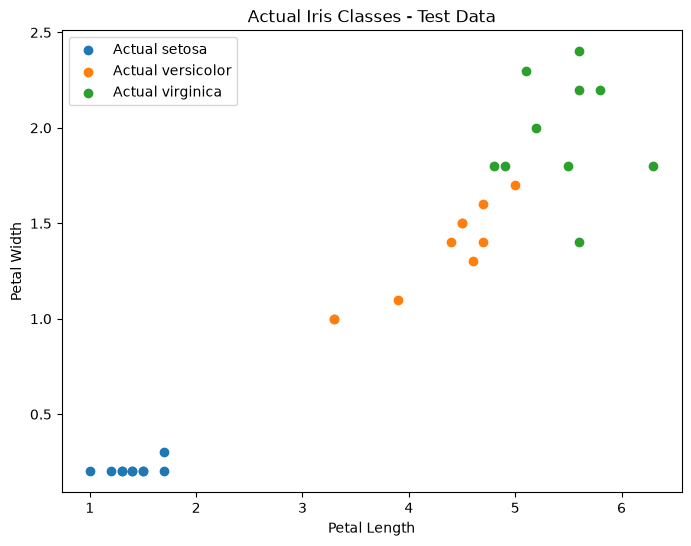

In [15]:
plt.figure(figsize=(8, 6))
for i, name in enumerate(iris.target_names):
    plt.scatter(X_test[y_test == i, 0], X_test[y_test == i, 1], label=f"Actual {name}")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Actual Iris Classes - Test Data")
plt.legend()
plt.show()

## 16. Predicted Test Classes

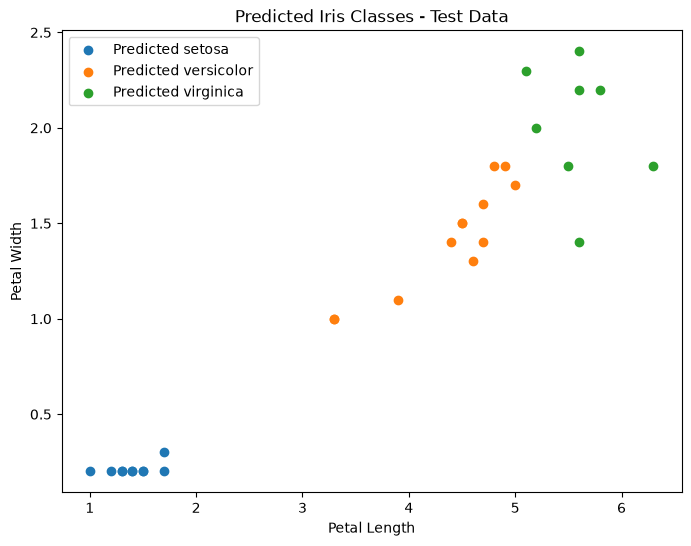

In [16]:
plt.figure(figsize=(8, 6))
for i, name in enumerate(iris.target_names):
    plt.scatter(X_test[y_test_pred == i, 0], X_test[y_test_pred == i, 1], label=f"Predicted {name}")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Predicted Iris Classes - Test Data")
plt.legend()
plt.show()